# 01 — Exploratory data analysis (EDA)

**Project:** CeDInt Storey 1 — energy waste & anomaly detection (TBDA 2026, Group 1)

**Why this notebook?** Before we build any model we need to know *what drives the electricity use* of each circuit.
The answers decide the target, the features and the model type in notebook 02. Every section asks one question,
answers it with a plot or table, and ends with **→ Finding** and **→ What it means for modelling**.

| # | Question |
|---|---|
| 1 | What data do we have, and which periods? |
| 2 | Where does the energy go? Which circuits matter for waste? |
| 3 | What does a normal day and week look like? |
| 4 | How much do weekends, holidays and breaks change the use? |
| 5 | How does outdoor weather relate to the use? |
| 6 | Is the use stable over the years (trend, drift)? |
| 7 | What happened during the COVID lockdown? |
| 8 | How much does the past predict the future (autocorrelation)? |
| 9 | How big is the night-time base load (potential waste)? |
| 10 | Are the indoor sensors (presence, light, temperature) useful? |
| 11 | Summary: decisions for modelling |

**Data:** `data/processed/cedint_hourly_v1.parquet` (frozen v1, see `MANIFEST.json`). Energy per hour = mean power `W` of that hour,
so **1 W during one hour = 1 Wh**. Times are local Madrid time.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))          # so we can import src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load, circuits, short, FOCUS, FIXED, FIG

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"eda_{name}.png", bbox_inches="tight")

full = load(drop_lockdown=False)                    # incl. COVID lockdown (only for section 1 and 7)
df = load()                                         # default: lockdown removed
A = df[df.Regime == "A"]                            # hourly period 2020-2023, used for most analysis
CIRC = circuits(df)
print(f"{len(full):,} hours in total, {len(df):,} without lockdown; {len(CIRC)} circuits")

26,830 hours in total, 24,911 without lockdown; 16 circuits


## 1. What data do we have?

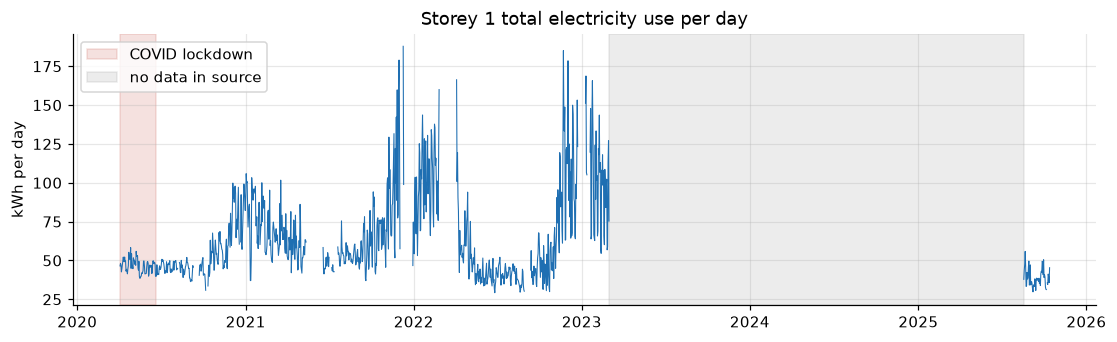

,start,end,hours,source sampling
Regime,,,,
A,2020-04-03 01:00:00,2023-03-01 00:00:00,25489,1 reading per hour
B,2025-08-18 20:00:00,2025-10-13 16:00:00,1341,1 reading per minute (averaged to hourly)


In [2]:
daily = full.set_index("timestamp_local")["STOREY1|TOTAL W"].resample("D").mean() * 24 / 1000   # kWh per day
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(daily.index, daily.values, lw=0.7, color="#1f6fb2")
ax.axvspan(pd.Timestamp("2020-04-02"), pd.Timestamp("2020-06-21"), color="#c0392b", alpha=0.15, label="COVID lockdown")
ax.axvspan(pd.Timestamp("2023-03-01"), pd.Timestamp("2025-08-18"), color="grey", alpha=0.15, label="no data in source")
ax.set_ylabel("kWh per day"); ax.set_title("Storey 1 total electricity use per day"); ax.legend(loc="upper left")
save(fig, "01_timeline"); plt.show()

summary = full.groupby("Regime").agg(start=("timestamp_local", "min"), end=("timestamp_local", "max"), hours=("timestamp_local", "size"))
summary["source sampling"] = ["1 reading per hour", "1 reading per minute (averaged to hourly)"]
summary

**→ Finding:** two separate periods: **Regime A** (Apr 2020 – Feb 2023, ~2.8 years) and **Regime B** (Aug – Oct 2025, 8 weeks).
The 2.5-year gap is in the source files. The lockdown (spring 2020) is visibly lower.

**→ What it means for modelling:** we train and validate on Regime A (enough history to learn seasons). Regime B is too
short to train on, so we use it as an **out-of-time check**: does a model trained on 2020-22 still describe the building in 2025?
Lockdown hours are removed from training because they are not normal use.

## 2. Where does the energy go?

,kWh per year,share of total %,used off-hours %,night median W,working-day 11-14h median W,group
NW Plugs & Sockets,11017.9,44.8,52.1,591.1,722.6,focus (waste possible)
SW Plugs & Sockets,2739.5,10.8,55.4,272.5,430.3,focus (waste possible)
SE Plugs & Sockets,2632.0,10.0,55.6,244.5,335.7,focus (waste possible)
NW Lighting,1726.9,7.0,69.7,119.9,74.4,focus (waste possible)
SW Lighting,1630.9,6.4,5.1,0.0,664.3,focus (waste possible)
NE Plugs & Sockets,1566.3,6.4,61.6,192.2,191.8,focus (waste possible)
NW RACK,1401.8,5.7,60.8,163.1,163.0,fixed load
NW HVAC,959.1,3.6,61.7,52.1,52.7,focus (waste possible)
SE HVAC,551.4,2.1,62.1,58.5,51.7,focus (waste possible)
SE Lighting,323.8,1.3,3.9,0.0,0.0,focus (waste possible)


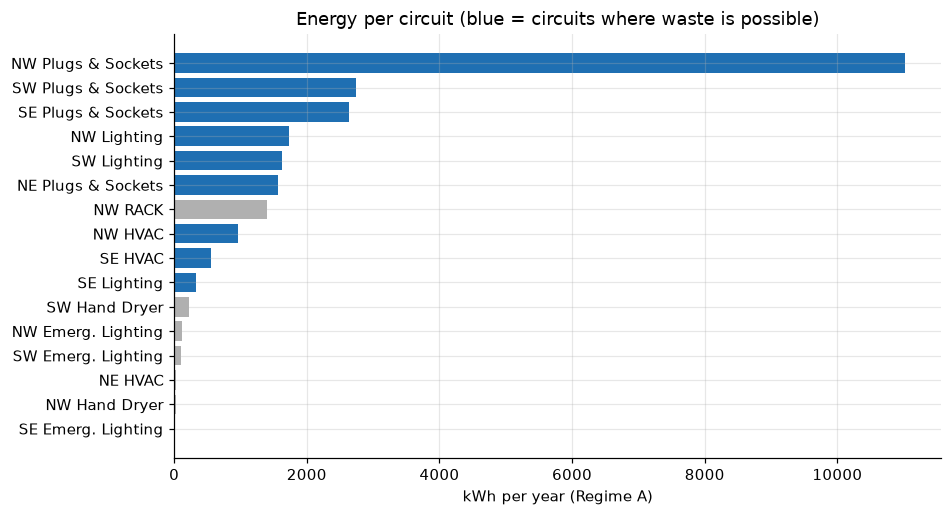

Off-hours = nights 22-06 + weekends + holidays + breaks = 61% of all hours


In [3]:
off = A["is_off_hours"]
tab = pd.DataFrame({
    "kWh per year": A[CIRC].mean() * 8760 / 1000,
    "share of total %": A[CIRC].sum() / A[CIRC].sum().sum() * 100,
    "used off-hours %": A.loc[off, CIRC].sum() / A[CIRC].sum() * 100,
    "night median W": A.loc[A.is_night, CIRC].median(),
    "working-day 11-14h median W": A.loc[A.is_working_day & A.hour_local.between(11, 13), CIRC].median(),
}).sort_values("kWh per year", ascending=False)
tab["group"] = ["focus (waste possible)" if c in FOCUS else "fixed load" for c in tab.index]
tab.index = [short(c) for c in tab.index]
display(tab.round(1))

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#1f6fb2" if g.startswith("focus") else "#b0b0b0" for g in tab["group"]]
ax.barh(tab.index[::-1], tab["kWh per year"][::-1], color=colors[::-1])
ax.set_xlabel("kWh per year (Regime A)"); ax.set_title("Energy per circuit (blue = circuits where waste is possible)")
save(fig, "02_energy_by_circuit"); plt.show()
print(f"Off-hours = nights 22-06 + weekends + holidays + breaks = {off.mean():.0%} of all hours")

**→ Finding:**
* **NW Plugs & Sockets uses ~45 % of all Storey 1 electricity** (≈11 MWh/year). The four plug circuits together are ~70 %.
* Plug circuits use **more than half of their energy off-hours**, and their **night median is close to the working-day median**
  (NW: ~590 W at night vs ~720 W at noon on working days). Something stays on when nobody is there.
* **NW Lighting** uses ~70 % of its energy off-hours and is *higher at night than at noon*, while SW/SE Lighting use almost nothing off-hours (see section 3).
* The "HVAC" circuits are small (< 4 %). The real heating seems to be electric heaters on the plug circuits (see section 5).
* Emergency lighting and the RACK are flat, always-on loads: no waste to find there.

Off-hours make up ~61 % of all hours in a year, so "used off-hours %" alone is not proof of waste: the night **base load** (section 9) is the key number.

**→ What it means for modelling:** we focus on the 9 *focus* circuits (plugs, lighting, NW/SE HVAC) and start with **NW Plugs & Sockets**.
Fixed loads are only monitored for sudden level changes.

## 3. What does a normal day and week look like?
Heatmap = average use for every hour of the week. Rows = day of week, columns = hour of the day.

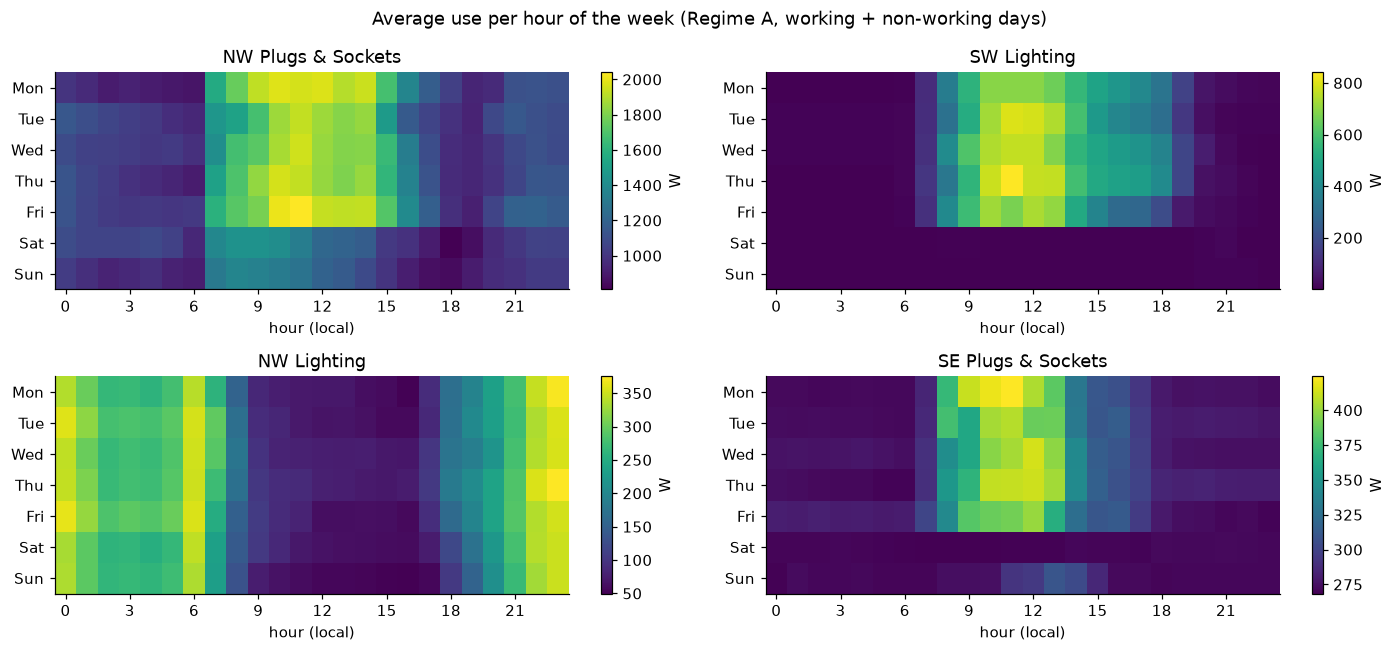

In [4]:
show = ["NW|Plugs & Sockets W", "SW|Lighting W", "NW|Lighting W", "SE|Plugs & Sockets W"]
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, axes = plt.subplots(2, 2, figsize=(13, 6))
for ax, c in zip(axes.flat, show):
    hm = A.pivot_table(index="weekday_local", columns="hour_local", values=c, aggfunc="mean")
    im = ax.imshow(hm, aspect="auto", cmap="viridis")
    ax.set_yticks(range(7), days); ax.set_xticks(range(0, 24, 3)); ax.grid(False)
    ax.set_title(short(c)); ax.set_xlabel("hour (local)")
    fig.colorbar(im, ax=ax, label="W")
fig.suptitle("Average use per hour of the week (Regime A, working + non-working days)")
fig.tight_layout(); save(fig, "03_week_heatmaps"); plt.show()

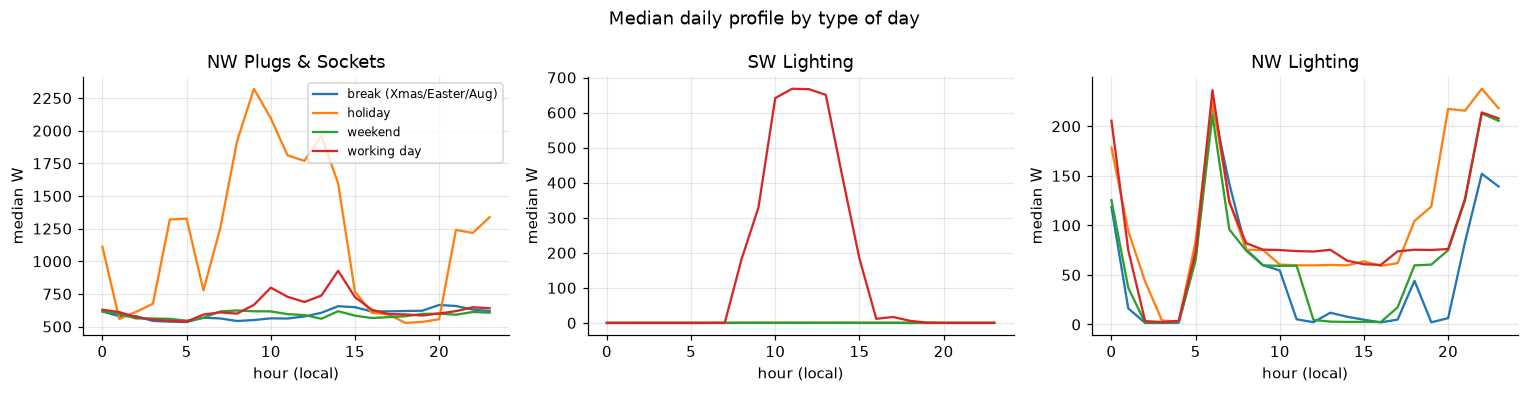

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharex=True)
for ax, c in zip(axes, ["NW|Plugs & Sockets W", "SW|Lighting W", "NW|Lighting W"]):
    for dt, g in A.groupby("day_type"):
        ax.plot(g.groupby("hour_local")[c].median(), label=dt)
    ax.set_title(short(c)); ax.set_xlabel("hour (local)"); ax.set_ylabel("median W")
axes[0].legend(fontsize=8)
fig.suptitle("Median daily profile by type of day"); fig.tight_layout(); save(fig, "03_daily_profiles"); plt.show()

**→ Finding:**
* Strong **daily cycle** on working days (≈ 7:00–20:00) and a strong **weekly cycle**.
* SW Lighting and SE Plugs are "textbook" circuits: on during working hours on Mon–Fri, low otherwise.
* NW Plugs has a high level **all the time** (≈ 1,000 W at night). It also **steps up at 07:00 on Saturdays and Sundays**,
  when nobody should be there — this looks like **heaters on a timer that ignores weekends**.
* NW Lighting does the opposite of normal lighting: **on from ≈ 22:00 to 07:00 every day, including weekends**, off during the day.
  It looks like a timer-controlled night / outdoor light. Whether it is needed is a question for the client (an easy saving if not).

**→ What it means for modelling:** features **hour of day**, **day of week** and their interaction are essential.
Tree models (LightGBM) learn this interaction automatically. A linear model needs it built in (hour × working-day dummies).

## 4. Weekends, holidays and breaks

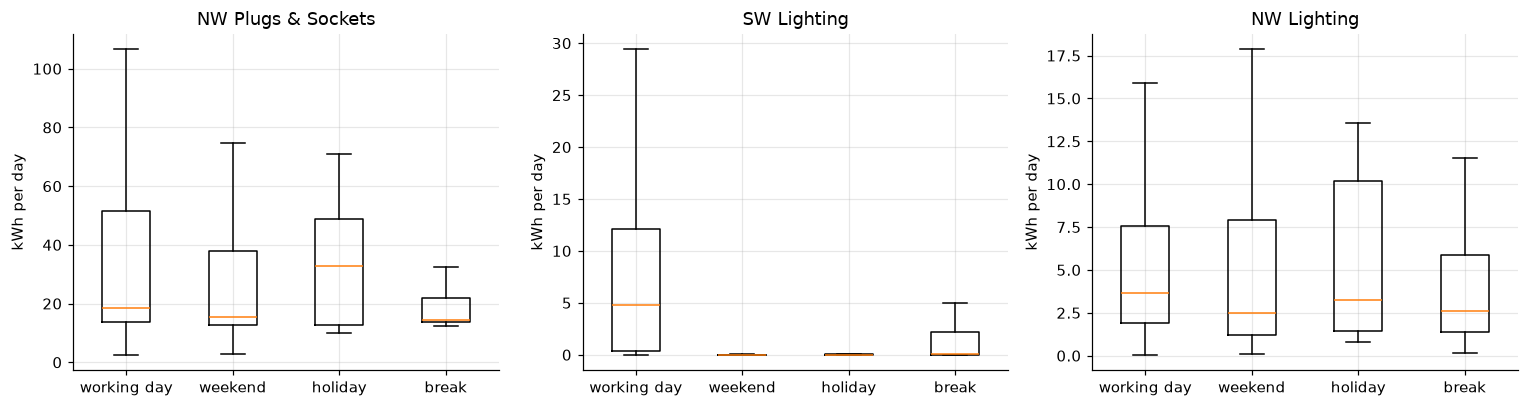

,NW Plugs & Sockets,SW Plugs & Sockets,SE Plugs & Sockets,SW Lighting,NW Lighting
day_type,,,,,
working day,18.5,7.7,6.6,4.8,3.7
weekend,15.3,6.4,5.8,0.0,2.5
holiday,32.9,6.3,6.7,0.0,3.3
break (Xmas/Easter/Aug),14.5,7.1,5.6,0.0,2.6


In [6]:
DAYCOLS = ["NW|Plugs & Sockets W", "SW|Plugs & Sockets W", "SE|Plugs & Sockets W", "SW|Lighting W", "NW|Lighting W"]
day = A.groupby("date_local").agg(day_type=("day_type", "first"), **{short(c): (c, "mean") for c in DAYCOLS})
for c in [short(c) for c in DAYCOLS]:
    day[c] = day[c] * 24 / 1000                      # kWh per day
order = ["working day", "weekend", "holiday", "break (Xmas/Easter/Aug)"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axes, ["NW Plugs & Sockets", "SW Lighting", "NW Lighting"]):
    ax.boxplot([day.loc[day.day_type == t, c].dropna() for t in order], tick_labels=[t.split(" (")[0] for t in order], showfliers=False)
    ax.set_title(c); ax.set_ylabel("kWh per day")
fig.tight_layout(); save(fig, "04_day_types"); plt.show()
day.groupby("day_type")[["NW Plugs & Sockets", "SW Plugs & Sockets", "SE Plugs & Sockets", "SW Lighting", "NW Lighting"]].median().loc[order].round(1)

**→ Finding:** SW Lighting drops to 0 on closed days, as it should. **NW Plugs uses ~83 % of its working-day energy on a normal weekend**
(15.3 vs 18.5 kWh/day), and on holidays even more (32.9 kWh/day) — most holidays are in winter (Christmas, January, December),
so the heaters are on in an empty building. That is the waste we want to price.

Note: the holiday number is **confounded by the season** (holidays ≈ winter). A model must look at calendar *and* temperature together,
otherwise it would learn "holidays use a lot" instead of "cold days use a lot".

**→ What it means for modelling:** the calendar flags from `build_calendar.py` (`is_working_day`, `is_holiday`, `is_break`, August)
are needed as features. A holiday on a Tuesday must look like a Sunday to the model.

## 5. Weather: does outdoor temperature drive the use?
One dot = one day. Outdoor temperature from Open-Meteo.

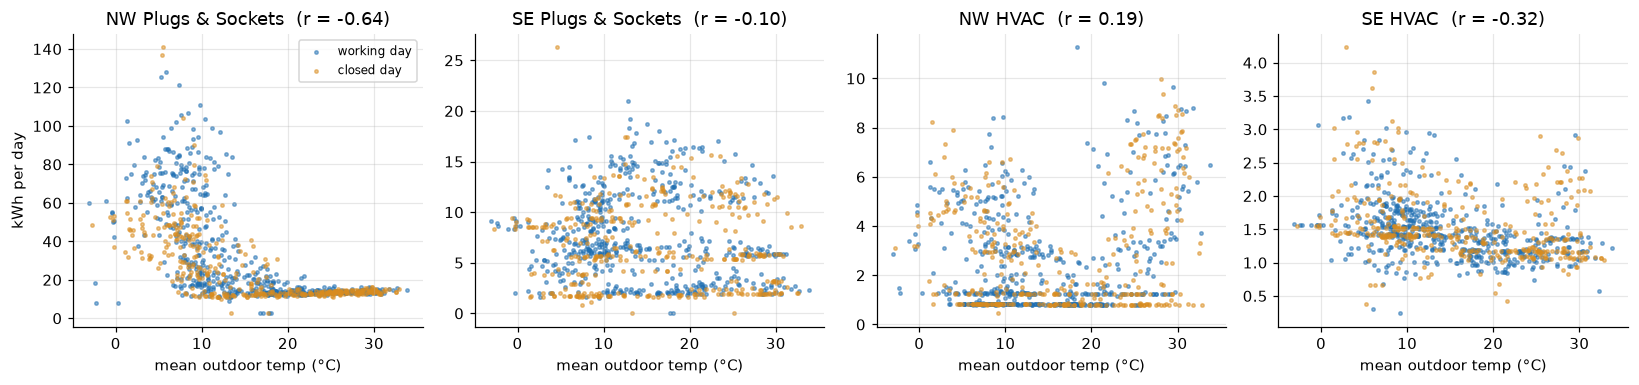

Correlation daily use vs outdoor temperature:
NW Plugs & Sockets   -0.64
SW Plugs & Sockets   -0.05
SE Plugs & Sockets   -0.10
NE Plugs & Sockets    0.11
NW Lighting          -0.18
SW Lighting          -0.32
SE Lighting          -0.22
NW HVAC               0.19
SE HVAC              -0.32


In [7]:
dd = A.groupby("date_local").agg(t=("wx_temp_c", "mean"), work=("is_working_day", "first"),
                                 **{c: (c, "mean") for c in FOCUS})
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, c in zip(axes, ["NW|Plugs & Sockets W", "SE|Plugs & Sockets W", "NW|HVAC W", "SE|HVAC W"]):
    for w, col, lab in [(True, "#1f6fb2", "working day"), (False, "#d98c1f", "closed day")]:
        g = dd[dd.work == w]
        ax.scatter(g.t, g[c] * 24 / 1000, s=5, alpha=0.5, color=col, label=lab)
    ax.set_title(f"{short(c)}  (r = {dd[c].corr(dd.t):.2f})"); ax.set_xlabel("mean outdoor temp (°C)")
axes[0].set_ylabel("kWh per day"); axes[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "05_temperature"); plt.show()

corr = pd.Series({short(c): dd[c].corr(dd.t) for c in FOCUS}).round(2)
print("Correlation daily use vs outdoor temperature:"); print(corr.to_string())

**→ Finding:** **NW Plugs & Sockets rises steeply when it is cold** (r ≈ −0.64): below ~12 °C the use roughly doubles to triples.
That is the signature of **electric heaters plugged into sockets** — and they also run on closed days (orange dots).
The HVAC circuits react only weakly to temperature.

**→ What it means for modelling:**
* Outdoor temperature is an important feature for the plug circuits. The relation is **non-linear** (flat when warm, steep when cold),
  so a linear model needs a "heating degree" feature: `max(0, 15 °C − T)`. A tree model finds the bend itself.
* Waste story for the client: *heaters left on in empty rooms during cold nights and weekends*.

## 6. Is the use stable over the years?

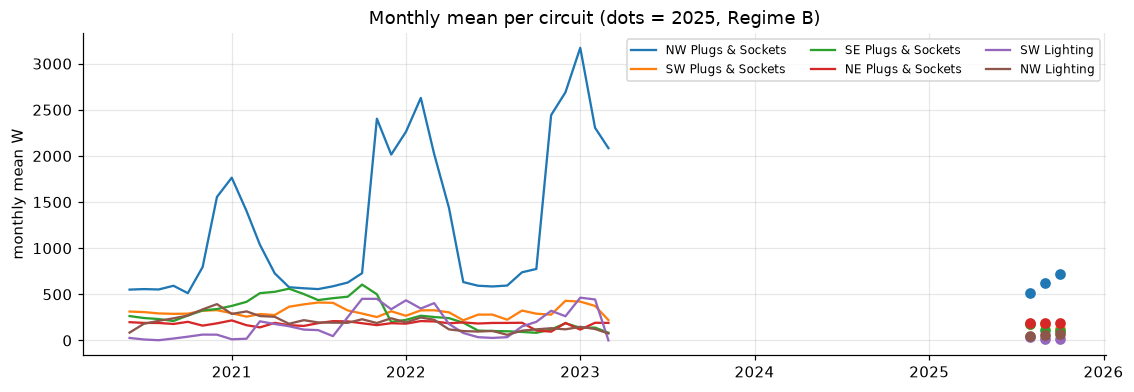

Mean W in January-February of each year (same season, so comparable):


,NW Plugs & Sockets,SW Plugs & Sockets,SE Plugs & Sockets,NE Plugs & Sockets
timestamp_local,,,,
2021,1593.0,277.0,395.0,192.0
2022,2437.0,296.0,245.0,195.0
2023,2753.0,399.0,138.0,153.0


In [8]:
m = A.set_index("timestamp_local")[FOCUS[:4] + ["SW|Lighting W", "NW|Lighting W"]].resample("MS").mean()
B = df[df.Regime == "B"].set_index("timestamp_local")[m.columns].resample("MS").mean()
fig, ax = plt.subplots(figsize=(12, 3.8))
for c in m.columns:
    line, = ax.plot(m.index, m[c], label=short(c))
    ax.plot(B.index, B[c], "o", color=line.get_color())
ax.set_ylabel("monthly mean W"); ax.set_title("Monthly mean per circuit (dots = 2025, Regime B)")
ax.legend(fontsize=8, ncol=3); save(fig, "06_monthly_trend"); plt.show()

yearly = A[A.timestamp_local.dt.month.isin([1, 2])].groupby(A.timestamp_local.dt.year)[FOCUS[:4]].mean().round(0)
yearly.columns = [short(c) for c in yearly.columns]
print("Mean W in January-February of each year (same season, so comparable):"); yearly

**→ Finding:** the level **is not stable**. NW Plugs has a strong winter peak every year and its winter level **grows every year** (Jan–Feb mean ≈ 1.6 → 2.4 → 2.8 kW for 2021 → 2022 → 2023;
more heaters / more people after COVID). SE Plugs goes the other way (it drops). In 2025 (Regime B, late summer) the levels are in line with earlier summers.

**→ What it means for modelling:**
* A model trained on old years under-predicts later winters. Two remedies: (1) a slowly moving **level feature** (recent typical use,
  measured at least one day back, so no leakage); (2) **time-based validation** that always tests on a later period than it trains on.
* This also means: **never use random cross-validation** here (lecture slide 41). Random splits would let the model peek at the future level.

## 7. COVID lockdown

In [9]:
lock = full[full.is_covid_lockdown]
after = full[(full.Regime == "A") & full.timestamp_local.between("2020-06-22", "2020-09-30")]
comp = pd.DataFrame({"lockdown (Apr-Jun 2020)": lock[CIRC].mean(), "after lockdown (Jun-Sep 2020)": after[CIRC].mean()}).loc[FOCUS]
comp.index = [short(c) for c in comp.index]
comp.round(0)

,lockdown (Apr-Jun 2020),after lockdown (Jun-Sep 2020)
NW Plugs & Sockets,549.0,563.0
SW Plugs & Sockets,302.0,298.0
SE Plugs & Sockets,270.0,235.0
NE Plugs & Sockets,222.0,187.0
NW Lighting,273.0,201.0
SW Lighting,4.0,11.0
SE Lighting,3.0,1.0
NW HVAC,91.0,158.0
SE HVAC,50.0,51.0


**→ Finding (surprising):** with the building closed, the plug circuits used **about the same** as in the summer months after the lockdown
(NW Plugs 549 vs 563 W). NW Lighting was even higher. In other words: in summer, most of the plug load is **always-on equipment**
that does not depend on people. That is a waste signal in itself.

**→ What it means for modelling:** lockdown hours are **excluded** from training (`load(drop_lockdown=True)`). They are only 82 days, they are a different
occupancy situation, and we do not want "empty building" to count as a normal working day.

## 8. How much does the past predict the future?
Autocorrelation = correlation of the series with itself *k* hours earlier.

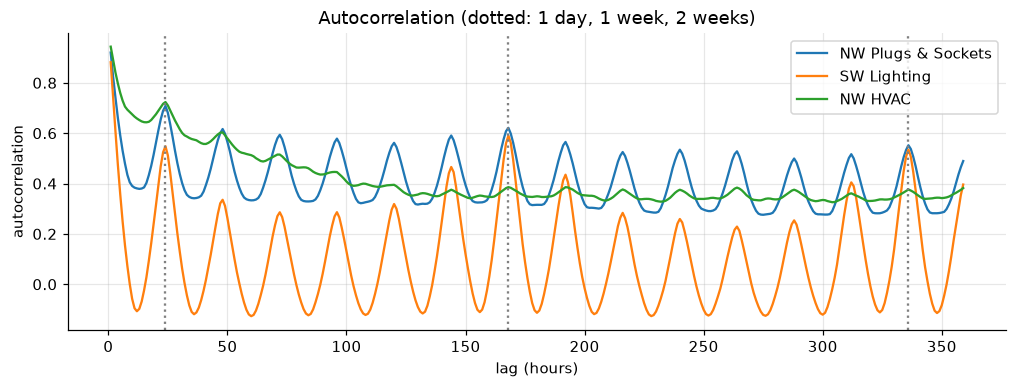

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.5))
lags = range(1, 24 * 15)
for c in ["NW|Plugs & Sockets W", "SW|Lighting W", "NW|HVAC W"]:
    s = A.set_index("timestamp_utc")[c].asfreq("h")
    ax.plot(list(lags), [s.autocorr(l) for l in lags], label=short(c))
for x in (24, 168, 336):
    ax.axvline(x, color="grey", ls=":")
ax.set_xlabel("lag (hours)"); ax.set_ylabel("autocorrelation"); ax.legend(); ax.set_title("Autocorrelation (dotted: 1 day, 1 week, 2 weeks)")
save(fig, "08_autocorr"); plt.show()

**→ Finding:** strong peaks at **24 h** and **168 h (1 week)**. The same hour yesterday / last week is very informative.

**→ What it means for modelling:**
* The simple baselines "same hour last week" (B1) and "median of the last 4 weeks" (B2) will be hard to beat, so they are our yardstick.
* Lag features at 24 h, 48 h, 168 h are useful, but **only lags of ≥ 24 h** (we predict a whole day ahead, and the last hour is not known in advance).
* **Important trade-off for waste detection:** if a heater is left on for 3 weeks, "last week" already contains the waste and the
  model learns it as normal. So for the anomaly model (notebook 03) we use a **normal-behaviour model** that relies on calendar, weather
  and a slow level, not on recent lags.

## 9. Night-time base load — how much could be saved?

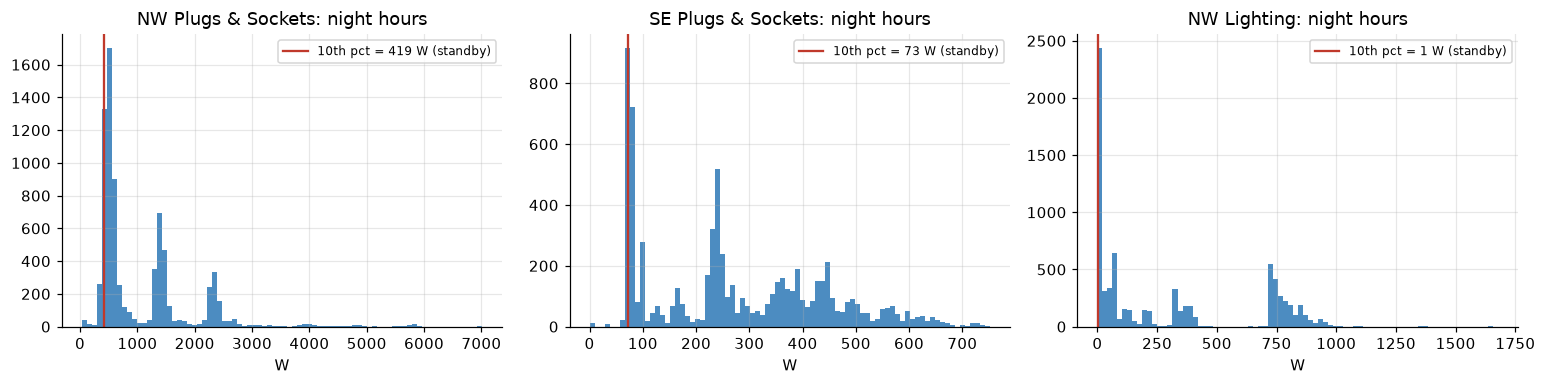

,standby W (10th pct night),off-hours excess kWh/year
circuit,,
NW Plugs & Sockets,419.0,3460.0
SW Plugs & Sockets,188.0,505.0
SE Plugs & Sockets,73.0,986.0
NE Plugs & Sockets,40.0,746.0
NW Lighting,1.0,1174.0
SW Lighting,0.0,80.0
SE Lighting,0.0,12.0
NW HVAC,34.0,380.0
SE HVAC,45.0,98.0


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, c in zip(axes, ["NW|Plugs & Sockets W", "SE|Plugs & Sockets W", "NW|Lighting W"]):
    night = A.loc[A.is_night, c].dropna()
    ax.hist(night, bins=80, color="#1f6fb2", alpha=0.8)
    p10 = night.quantile(0.10)
    ax.axvline(p10, color="#c0392b", label=f"10th pct = {p10:.0f} W (standby)")
    ax.set_title(f"{short(c)}: night hours"); ax.set_xlabel("W"); ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "09_night_load"); plt.show()

rows = []
for c in FOCUS:
    s = A[c]; standby = s[A.is_night].quantile(0.10)
    excess = (s[A.is_off_hours] - standby).clip(lower=0)
    rows.append({"circuit": short(c), "standby W (10th pct night)": standby,
                 "off-hours excess kWh/year": excess.sum() / 1000 / (len(A) / 8760)})
pd.DataFrame(rows).set_index("circuit").round(0)

**→ Finding:** night use is spread widely above the lowest ("standby") level. The energy used off-hours **above standby** is a first,
simple estimate of avoidable use (this is the rule-based approach the Sprint 2 report used: 5.5–7.9 MWh/year).

**→ What it means for modelling:** we keep this rule as a transparent **second signal** next to the model. In notebook 03 an hour is
flagged when it is *both* off-hours *and* clearly above what the model expects.

## 10. Indoor sensors: presence, light, indoor temperature

In [12]:
env = [c for c in A.columns if "|ENV" in c]
print("Missing share of indoor sensors:"); print(A[env].isna().mean().round(2).to_string())
pres = "NW|ENV Pres share"
print("\nNW presence value counts (share of the hour with presence):"); print(A[pres].round(1).value_counts().sort_index().head(12).to_string())
cc = A[[pres, "NW|ENV Lum lux", "NW|ENV Temp °C", "NW|Plugs & Sockets W", "NW|Lighting W", "hour_local"]].corr().round(2)
cc

Missing share of indoor sensors:
NW|ENV Hum %RH       0.02
NW|ENV Lum lux       0.02
NW|ENV Pres share    0.02
NW|ENV Temp °C       0.02
SE|ENV Hum %RH       0.05
SE|ENV Lum lux       0.05
SE|ENV Pres share    0.05
SE|ENV Temp °C       0.05
SW|ENV Hum %RH       0.05
SW|ENV Lum lux       0.05
SW|ENV Pres share    0.05
SW|ENV Temp °C       0.05

NW presence value counts (share of the hour with presence):
NW|ENV Pres share
0.0    12201
1.0    10930


,NW|ENV Pres share,NW|ENV Lum lux,NW|ENV Temp °C,NW|Plugs & Sockets W,NW|Lighting W,hour_local
NW|ENV Pres share,1.00,0.10,-0.04,0.04,-0.00,0.05
NW|ENV Lum lux,0.10,1.00,0.36,-0.07,-0.39,0.26
NW|ENV Temp °C,-0.04,0.36,1.00,-0.44,-0.13,0.19
NW|Plugs & Sockets W,0.04,-0.07,-0.44,1.00,-0.05,-0.00
NW|Lighting W,-0.00,-0.39,-0.13,-0.05,1.00,-0.09
hour_local,0.05,0.26,0.19,-0.00,-0.09,1.00


**→ Finding:** the presence sensor is rarely missing (2–5 %), but it is binary (0 or 1), says "present" in ~47 % of all hours
(nights included) and is **barely correlated** with the hour of day or with consumption (≈ 0.05). It does not measure occupancy reliably.
Indoor light and temperature are partly *caused by* the circuits we predict (lights raise lux, heaters raise temperature).

**→ What it means for modelling:** indoor sensors are **not used as features**: presence is too unreliable, and lux / indoor temperature
in the same hour are an effect of the target (a form of leakage). Outdoor weather is used instead. For the same reason `I`, `Pa`, `Ea`
of the same hour are never features.

## 11. Summary — decisions for modelling

| Question | Finding | Decision |
|---|---|---|
| Target | Energy per hour per circuit; NW Plugs is 45 % of use | Target = Wh per hour (mean W) per circuit; start with NW Plugs, then all 9 focus circuits |
| Periods | 2020-23 hourly, 2025 8 weeks, lockdown abnormal | Train/validate/test on 2020-23 by time; 2025 = out-of-time check; drop lockdown |
| Daily/weekly cycle | very strong, holidays look like Sundays | Features: hour, weekday, working-day / holiday / break / August flags |
| Weather | heating via plugs, non-linear in temperature | Features: outdoor temp, heating degrees `max(0, 15−T)`, solar radiation |
| Trend | level grows from year to year | Slow level feature (≥ 1 day old) + time-based validation only |
| Autocorrelation | strong at 24 h and 168 h | Baselines B1/B2; lags ≥ 24 h for the forecast model; *no short lags* in the normal-behaviour (anomaly) model |
| Waste | high night base load, NW Lighting on at night | Anomaly = model residual + off-hours rule, valued in € and CO₂ |
| Indoor sensors | unreliable / caused by target | Not used as features |

**Model ladder (lecture: start simple, then earn complexity):** baselines → Ridge regression (linear, with engineered features) →
LightGBM (gradient-boosted trees, strong for tabular data). Deep learning is not justified: tabular data, ~20k hours per circuit,
and boosted trees are a hard baseline to beat (lecture slides 22 and 30).